## Lab 3

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

C:\Users\icha\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


### Step 1 - Load Image Data

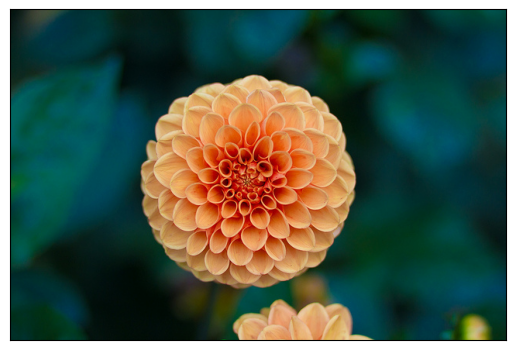

In [2]:
from sklearn.datasets import load_sample_image
flower = load_sample_image("flower.jpg")
ax = plt.axes(xticks=[], yticks=[])
ax.imshow(flower)

### Step 2 - Preprocessing

In [3]:
# Check shape
print(flower.shape)

# Normalize color
data = flower / 255.0

# Reshape
data = data.reshape(427 * 640, 3) # turn to 1D

print(data.shape)

(427, 640, 3)
(273280, 3)


### Step 3 - Examine Color Distribution

In [16]:
def plot_pixels(data, title, colors=None, N=10000):
    data = np.asarray(data)

    if data.ndim != 2 or data.shape[1] != 3:
        raise ValueError(
            f"Data harus berupa RGB dengan bentuk (n_samples, 3), "
            f"tetapi bentuknya {data.shape}"
        )

    if colors is None:
        colors = data.copy()

    colors = np.asarray(colors, dtype=float)

    # Normalisasi warna hanya jika data masih berada pada rentang 0-255
    if colors.max() > 1:
        colors = colors / 255.0

    rng = np.random.RandomState(0)
    i = rng.permutation(data.shape[0])[:N]

    R, G, B = data[i].T
    if data.max() > 1:
        R, G, B = R / 255.0, G / 255.0, B / 255.0

    colors = np.clip(colors[i], 0, 1)

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    ax[0].scatter(R, G, color=colors, s=10)
    ax[0].set_xlabel("Red")
    ax[0].set_ylabel("Green")

    ax[1].scatter(R, B, color=colors, s=10)
    ax[1].set_xlabel("Red")
    ax[1].set_ylabel("Blue")

    fig.suptitle(title)
    plt.show()

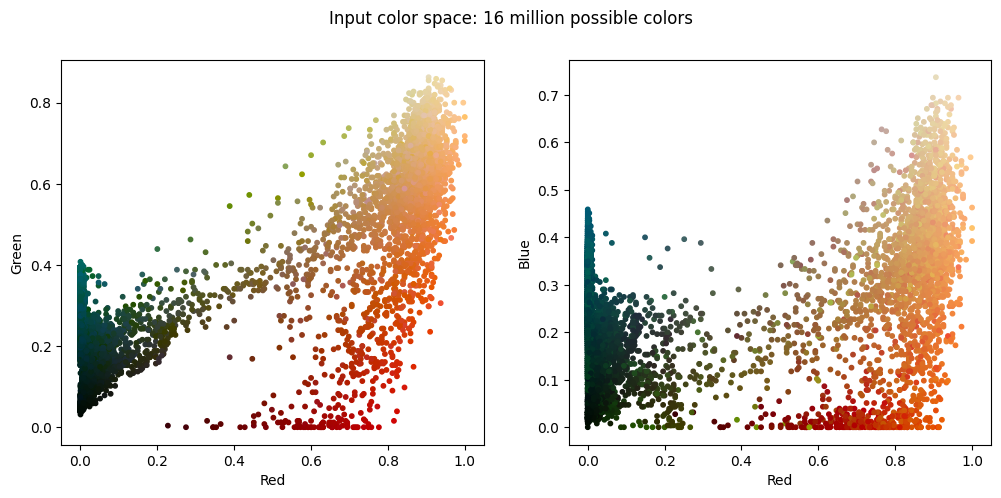

In [17]:
plot_pixels(data, title='Input color space: 16 million possible colors')

### Step 4 - Color Clustering

c:\Users\icha\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\icha\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\icha\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\icha\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^

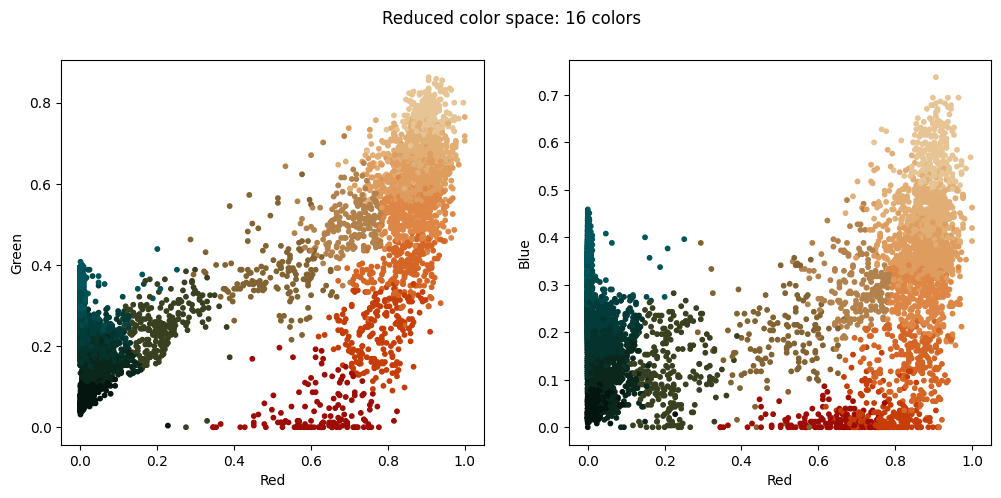

In [18]:
from sklearn.cluster import MiniBatchKMeans

kmeans = MiniBatchKMeans(16)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]

plot_pixels(data, colors=new_colors,title="Reduced color space: 16 colors")

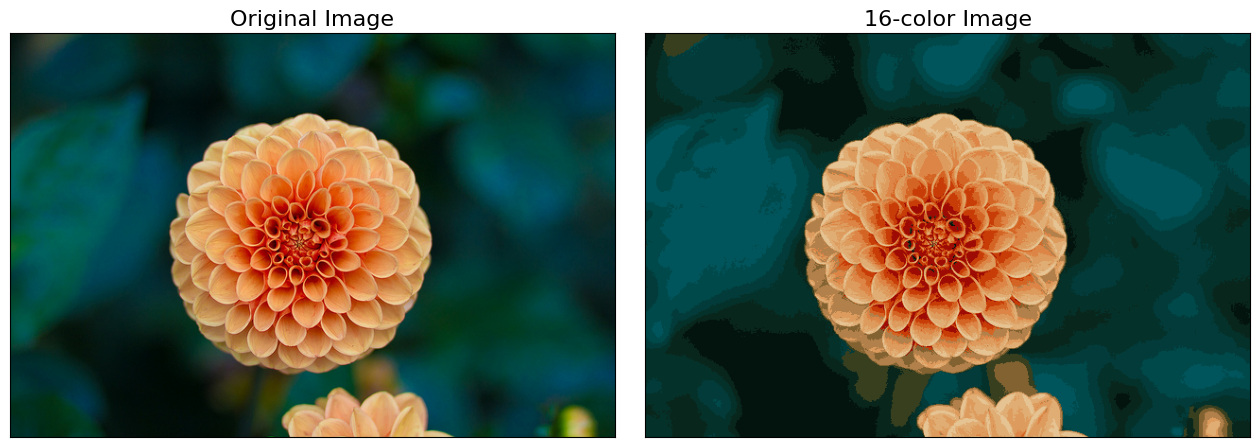

In [19]:
flower_recolored = new_colors.reshape(flower.shape)

fig, ax = plt.subplots(1, 2, figsize=(16, 6),
                       subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(flower)
ax[0].set_title('Original Image', size=16)
ax[1].imshow(flower_recolored)
ax[1].set_title('16-color Image', size=16);